In [1]:
# ===============================
# Imports & configuration
# ===============================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from adjustText import adjust_text
import statsmodels.api as sm
from scipy.stats import norm, kurtosis, skew
from pandas_datareader import data as pdr
import cvxpy as cp

from pypfopt import (
    EfficientFrontier,
    risk_models,
    expected_returns,
    HRPOpt,
)

from arch import arch_model

# === Import all utility functions ===
from utils import (
    port_data_load_prices_bbg,      
    port_data_compute_returns,
    port_data_load_benchmark_bbg,
    port_metrics_compute_portfolio_series,
    port_metrics_expected_annual_return,
    port_metrics_volatility_annual,
    port_metrics_sharpe_ratio,
    port_metrics_sortino_ratio,
    port_metrics_drawdown_max,
    port_metrics_summarize,
    port_utils_clean_weights,
    port_table_build_weights,
    port_table_build_metrics,
    port_data_summary_assets,
)

In [2]:
# -------------------------------
# User-adjustable parameters
# -------------------------------   

start_date_text = "2016-10-01"   
end_date_text = "2021-09-30"

# All available Bloomberg assets # <----- MODIFY AS NEEDED!
assets_list = [
    "SMH",   # VanEck Vectors Semiconductor ETF
    "USMV",  # iShares MSCI USA Min Vol Factor ETF
    "GDX",   # VanEck Gold Miners ETF
    "VB",    # Vanguard Small-Cap ETF
    "QQQ",   # Invesco QQQ Trust
    "TAN",   # Invesco Solar ETF
    "IVV",   # iShares Core S&P 500 ETF
    "XLF",   # Financial Select Sector SPDR Fund
    "NBCM",  # Nuveen Nasdaq 100 Dynamic Overwrite Fund
    "VYM",   # Vanguard High Dividend Yield ETF
    "GLD",   # SPDR Gold Shares
    "XLV",   # Health Care Select Sector SPDR Fund
    "VOO",   # Vanguard S&P 500 ETF
    "AIVC",  # Amplify International Online Retail ETF
    "XLK",   # Technology Select Sector SPDR Fund
    "SPY",   # SPDR S&P 500 ETF Trust
    "IGSB",  # iShares Short-Term Corporate Bond ETF
    "IEFA",  # iShares MSCI EAFE ETF
    "EQQQ",  # Invesco EQQQ NASDAQ-100 UCITS ETF
    "IEMG",  # iShares Core MSCI Emerging Markets ETF
]

benchmark_csv_path      = "benchmark.csv"  # located in bloomberg_data/
risk_free_rate_annual   = 0.035
trading_days_per_year   = 252

In [3]:
# ===========================================
# Load Data (Daily)
# ===========================================

prices_frame = port_data_load_prices_bbg(assets_list, start_date_text, end_date_text)
returns_frame = port_data_compute_returns(prices_frame)

# Load benchmark (same Bloomberg format)
benchmark_return_series = port_data_load_benchmark_bbg(
    data_directory="bloomberg_data",
    file_name=benchmark_csv_path,
    start_date_text=start_date_text,
    end_date_text=end_date_text,
)

# Align all data to common calendar
common_index = returns_frame.index.intersection(benchmark_return_series.index)
prices_frame  = prices_frame.loc[common_index]
returns_frame = returns_frame.loc[common_index]
benchmark_return_series = benchmark_return_series.loc[common_index]


--- Bloomberg Price Data Loading ---
[INFO] Date range: 2016-10-03 → 2021-09-30
[WARN] Remaining NaNs detected after alignment (forward-filled):
       EQQQ: 1 NaNs | first: ['2016-10-03'] | last: ['2016-10-03']
[INFO] Loaded tickers: ['SMH', 'USMV', 'GDX', 'VB', 'QQQ', 'TAN', 'IVV', 'XLF', 'NBCM', 'VYM', 'GLD', 'XLV', 'VOO', 'AIVC', 'XLK', 'SPY', 'IGSB', 'IEFA', 'EQQQ', 'IEMG']
[INFO] Missing values handled using forward fill.
--- End Bloomberg Price Data Loading ---


--- Bloomberg Benchmark Loading ---
[INFO] No NaNs detected. Data fully continuous.
[INFO] Date range: 2016-10-04 → 2021-09-30
[INFO] Missing values handled using forward fill.
--- End Bloomberg Benchmark Loading ---



In [4]:
# ===============================
# Asset Diagnostics
# ===============================

asset_summary = port_data_summary_assets(
    returns_frame,
    benchmark_return_series=benchmark_return_series,
    risk_free_rate_annual=risk_free_rate_annual,
    trading_days_per_year=trading_days_per_year
)


[INFO] Using entire available period for analysis.

--- Asset Annualized Performance Summary ---
[INFO] Analysis period: 2016-10-05 → 2021-09-30

           Mean (Ann.)  Vol (Ann.)  Sharpe (Ann.)  Sortino (Ann.)  TE (Ann.)  \
SMH           0.311537    0.295624       0.935434        1.479830   0.231974   
USMV          0.128435    0.161217       0.579562        0.852783   0.087599   
GDX           0.115840    0.363357       0.222480        0.359229   0.352293   
VB            0.153366    0.218182       0.542510        0.805275   0.142304   
QQQ           0.246366    0.218811       0.965973        1.472519   0.148264   
TAN           0.345505    0.360829       0.860531        1.394721   0.310129   
IVV           0.170931    0.188588       0.720782        1.065023   0.106644   
XLF           0.182358    0.249879       0.589717        0.914625   0.184613   
NBCM          0.068636    0.134709       0.249691        0.369193   0.120089   
VYM           0.119858    0.182134       0.465913    

In [5]:
# ===============================
# Portfolio Optimization
# ===============================

# --- Estimate expected returns and covariance ---
mu_series = expected_returns.mean_historical_return(prices_frame)
cov_matrix = risk_models.sample_cov(prices_frame)
cov_matrix_lw = risk_models.CovarianceShrinkage(prices_frame).ledoit_wolf()


# --- Markowitz (constrained) ---
ef_markowitz_constrained = EfficientFrontier(mu_series, cov_matrix, weight_bounds=(0.02, 0.15))
weights_markowitz_constrained_dict = ef_markowitz_constrained.max_sharpe(risk_free_rate=risk_free_rate_annual)
weights_markowitz_constrained_series = port_utils_clean_weights(ef_markowitz_constrained.clean_weights())


# --- Markowitz (constrained, LW shrinkage) ---
ef_markowitz_constrained_lw = EfficientFrontier(mu_series, cov_matrix_lw, weight_bounds=(0.02, 0.15))
weights_markowitz_constrained_lw_dict = ef_markowitz_constrained_lw.max_sharpe(risk_free_rate=risk_free_rate_annual)
weights_markowitz_constrained_lw_series = port_utils_clean_weights(ef_markowitz_constrained_lw.clean_weights())


# --- Markowitz (classic, unconstrained) ---
ef_markowitz_classic = EfficientFrontier(mu_series, cov_matrix)
weights_markowitz_classic_dict = ef_markowitz_classic.max_sharpe(risk_free_rate=risk_free_rate_annual)
weights_markowitz_classic_series = port_utils_clean_weights(ef_markowitz_classic.clean_weights())


# --- Markowitz (classic, unconstrained, LW shrinkage) ---
ef_markowitz_classic_lw = EfficientFrontier(mu_series, cov_matrix_lw)
weights_markowitz_classic_lw_dict = ef_markowitz_classic_lw.max_sharpe(risk_free_rate=risk_free_rate_annual)
weights_markowitz_classic_lw_series = port_utils_clean_weights(ef_markowitz_classic_lw.clean_weights())


# --- Minimum variance portfolio (constrained) ---
ef_minvar_constrained = EfficientFrontier(mu_series, cov_matrix, weight_bounds=(0.02, 0.15))
weights_minvar_constrained_dict = ef_minvar_constrained.min_volatility()
weights_minvar_constrained_series = port_utils_clean_weights(ef_minvar_constrained.clean_weights())


# --- Minimum variance portfolio (constrained, LW shrinkage) ---
ef_minvar_constrained_lw = EfficientFrontier(mu_series, cov_matrix_lw, weight_bounds=(0.02, 0.15))
weights_minvar_constrained_lw_dict = ef_minvar_constrained_lw.min_volatility()
weights_minvar_constrained_lw_series = port_utils_clean_weights(ef_minvar_constrained_lw.clean_weights())


# --- Minimum variance portfolio (unconstrained) ---
ef_minvar = EfficientFrontier(mu_series, cov_matrix)
weights_minvar_dict = ef_minvar.min_volatility()
weights_minvar_series = port_utils_clean_weights(ef_minvar.clean_weights())


# --- Minimum variance portfolio (unconstrained, LW shrinkage) ---
ef_minvar_lw = EfficientFrontier(mu_series, cov_matrix_lw)
weights_minvar_lw_dict = ef_minvar_lw.min_volatility()
weights_minvar_lw_series = port_utils_clean_weights(ef_minvar_lw.clean_weights())


# --- Hierarchical Risk Parity (HRP) ---
returns_standardized = returns_frame / returns_frame.std(ddof=0)
hrp_model = HRPOpt(returns_standardized)
weights_riskparity_dict = hrp_model.optimize()
weights_riskparity_series = port_utils_clean_weights(weights_riskparity_dict)


# --- Maximum Decorrelation Portfolio ---
corr_matrix = risk_models.cov_to_corr(cov_matrix)
my_weights_variable = cp.Variable(corr_matrix.shape[0])
my_objective = cp.quad_form(my_weights_variable, corr_matrix)
my_constraints = [cp.sum(my_weights_variable) == 1, my_weights_variable >= 0]
cp.Problem(cp.Minimize(my_objective), my_constraints).solve()
weights_decorrel_series = pd.Series(np.array(my_weights_variable.value).ravel(), index=corr_matrix.columns)
weights_decorrel_series = port_utils_clean_weights(weights_decorrel_series.to_dict())


# --- Maximum Decorrelation Portfolio (LW shrinkage) ---
corr_matrix_lw = risk_models.cov_to_corr(cov_matrix_lw)
my_weights_variable = cp.Variable(corr_matrix_lw.shape[0])
my_objective = cp.quad_form(my_weights_variable, corr_matrix_lw)
my_constraints = [cp.sum(my_weights_variable) == 1, my_weights_variable >= 0]
cp.Problem(cp.Minimize(my_objective), my_constraints).solve()
weights_decorrel_lw_series = pd.Series(np.array(my_weights_variable.value).ravel(), index=corr_matrix_lw.columns)
weights_decorrel_lw_series = port_utils_clean_weights(weights_decorrel_lw_series.to_dict())


# --- Equal-weight portfolio ---
weights_equal_series = pd.Series(1 / len(returns_frame.columns), index=returns_frame.columns)


# --- Value-weighted portfolio (by market cap) ---
def port_data_get_market_caps(tickers_list):
    caps_dict = {}
    for tkr in tickers_list:
        try:
            caps_dict[tkr] = yf.Ticker(tkr).info.get("marketCap", np.nan)
        except Exception:
            caps_dict[tkr] = np.nan
    caps_series = pd.Series(caps_dict).dropna()
    caps_series = caps_series / caps_series.sum()
    return caps_series

weights_value_series = port_data_get_market_caps(assets_list)
weights_value_series = weights_value_series.reindex(returns_frame.columns).fillna(0.0)


# --- Naive Risk Budgeting (Inverse Volatility) ---
inv_vol_series = 1.0 / returns_frame.std(ddof=0).replace([np.inf, -np.inf], np.nan)
inv_vol_series = inv_vol_series.fillna(0.0)
weights_inversevol_series = inv_vol_series / inv_vol_series.sum()

In [6]:
# ===============================
# Portfolio & Benchmark Metrics
# ===============================

# --- Compute metrics for each optimized portfolio ---

metrics_markowitz_classic = port_metrics_summarize(weights_markowitz_classic_series, returns_frame, benchmark_return_series, risk_free_rate_annual, trading_days_per_year)
metrics_markowitz_classic_lw = port_metrics_summarize(weights_markowitz_classic_lw_series, returns_frame, benchmark_return_series, risk_free_rate_annual, trading_days_per_year)
metrics_markowitz_constrained = port_metrics_summarize(weights_markowitz_constrained_series, returns_frame, benchmark_return_series, risk_free_rate_annual, trading_days_per_year)
metrics_markowitz_constrained_lw = port_metrics_summarize(weights_markowitz_constrained_lw_series, returns_frame, benchmark_return_series, risk_free_rate_annual, trading_days_per_year)

metrics_minvar = port_metrics_summarize(weights_minvar_series, returns_frame, benchmark_return_series, risk_free_rate_annual, trading_days_per_year)
metrics_minvar_lw = port_metrics_summarize(weights_minvar_lw_series, returns_frame, benchmark_return_series, risk_free_rate_annual, trading_days_per_year)
metrics_minvar_constrained = port_metrics_summarize(weights_minvar_constrained_series, returns_frame, benchmark_return_series, risk_free_rate_annual, trading_days_per_year)
metrics_minvar_constrained_lw = port_metrics_summarize(weights_minvar_constrained_lw_series, returns_frame, benchmark_return_series, risk_free_rate_annual, trading_days_per_year)

metrics_decorrel = port_metrics_summarize(weights_decorrel_series, returns_frame, benchmark_return_series, risk_free_rate_annual, trading_days_per_year)
metrics_decorrel_lw = port_metrics_summarize(weights_decorrel_lw_series, returns_frame, benchmark_return_series, risk_free_rate_annual, trading_days_per_year)

metrics_riskparity = port_metrics_summarize(weights_riskparity_series, returns_frame, benchmark_return_series, risk_free_rate_annual, trading_days_per_year)

metrics_equal = port_metrics_summarize(weights_equal_series, returns_frame, benchmark_return_series, risk_free_rate_annual, trading_days_per_year)
metrics_value = port_metrics_summarize(weights_value_series, returns_frame, benchmark_return_series, risk_free_rate_annual, trading_days_per_year)

metrics_inversevol = port_metrics_summarize(weights_inversevol_series, returns_frame, benchmark_return_series, risk_free_rate_annual, trading_days_per_year)

# --- Benchmark metrics ---
benchmark_metrics = {"expected_return_annual": port_metrics_expected_annual_return(benchmark_return_series, trading_days_per_year),
                     "volatility_annual": port_metrics_volatility_annual(benchmark_return_series, trading_days_per_year),
                     "sharpe_ratio": port_metrics_sharpe_ratio(benchmark_return_series, risk_free_rate_annual, trading_days_per_year),
                     "sortino_ratio": port_metrics_sortino_ratio(benchmark_return_series, risk_free_rate_annual, trading_days_per_year),
                     "max_drawdown": port_metrics_drawdown_max(benchmark_return_series),
                     "tracking_error_annual": np.nan,
                     "information_ratio": np.nan}

In [7]:
# ===============================
# Results
# ===============================

# --- Combine all portfolio weights (keep 0s visible) ---
weights_table = (
    port_table_build_weights(weights_markowitz_classic_series, "markowitz_classic")
    .join(port_table_build_weights(weights_markowitz_classic_lw_series, "markowitz_classic_LW"), how="outer")
    .join(port_table_build_weights(weights_markowitz_constrained_series, "markowitz_constrained"), how="outer")
    .join(port_table_build_weights(weights_markowitz_constrained_lw_series, "markowitz_constrained_LW"), how="outer")
    .join(port_table_build_weights(weights_minvar_series, "minimum_variance"), how="outer")
    .join(port_table_build_weights(weights_minvar_lw_series, "minimum_variance_LW"), how="outer")
    .join(port_table_build_weights(weights_minvar_constrained_series, "minimum_variance_constrained"), how="outer")
    .join(port_table_build_weights(weights_minvar_constrained_lw_series, "minimum_variance_LW_constrained"), how="outer")
    .join(port_table_build_weights(weights_decorrel_series, "max_decorrelation"), how="outer")
    .join(port_table_build_weights(weights_decorrel_lw_series, "max_decorrelation_LW"), how="outer")
    .join(port_table_build_weights(weights_riskparity_series, "risk_parity_hrp"), how="outer")
    .join(port_table_build_weights(weights_equal_series, "equal_weighted"), how="outer")
    .join(port_table_build_weights(weights_value_series, "value_weighted"), how="outer")
    .join(port_table_build_weights(weights_inversevol_series, "naive_inverse_volatility"), how="outer")
).fillna(0.0)   # <== keeps zeros so portfolio weights always sum to 1 visibly


# --- Combine all metrics ---
metrics_table = pd.concat(
    [
        port_table_build_metrics(metrics_markowitz_classic, "markowitz_classic"),
        port_table_build_metrics(metrics_markowitz_classic_lw, "markowitz_classic_LW"),
        port_table_build_metrics(metrics_markowitz_constrained, "markowitz_constrained"),
        port_table_build_metrics(metrics_markowitz_constrained_lw, "markowitz_constrained_LW"),
        port_table_build_metrics(metrics_minvar, "minimum_variance"),
        port_table_build_metrics(metrics_minvar_lw, "minimum_variance_LW"),
        port_table_build_metrics(metrics_minvar_constrained, "minimum_variance_constrained"),
        port_table_build_metrics(metrics_minvar_constrained_lw, "minimum_variance_LW_constrained"),
        port_table_build_metrics(metrics_decorrel, "max_decorrelation"),
        port_table_build_metrics(metrics_decorrel_lw, "max_decorrelation_LW"),
        port_table_build_metrics(metrics_riskparity, "risk_parity_hrp"),
        port_table_build_metrics(metrics_equal, "equal_weighted"),
        port_table_build_metrics(metrics_value, "value_weighted"),
        port_table_build_metrics(metrics_inversevol, "naive_inverse_volatility"),
        port_table_build_metrics(benchmark_metrics, "benchmark"),
    ],
    axis=0,
)


# --- Rename columns for readability ---
metrics_table = metrics_table.rename(columns={
    "expected_return_annual": "Return (Ann.)",
    "volatility_annual": "Vol (Ann.)",
    "max_drawdown": "Max DD",
    "sharpe_ratio": "Sharpe (Ann.)",
    "sortino_ratio": "Sortino (Ann.)",
    "tracking_error_annual": "TE (Ann.)",
    "information_ratio": "Info (Ann.)"
})[
    ["Return (Ann.)", "Vol (Ann.)", "Max DD",
     "Sharpe (Ann.)", "Sortino (Ann.)", "TE (Ann.)", "Info (Ann.)"]
]


# --- Enforce logical family ordering for both tables ---
ordered_names = [
    "markowitz_classic", "markowitz_classic_LW",
    "markowitz_constrained", "markowitz_constrained_LW",
    "minimum_variance", "minimum_variance_LW",
    "minimum_variance_constrained", "minimum_variance_LW_constrained",
    "max_decorrelation", "max_decorrelation_LW",
    "risk_parity_hrp",
    "equal_weighted",
    "value_weighted",
    "naive_inverse_volatility",
    "benchmark"
]

metrics_table = metrics_table.loc[ordered_names]
weights_table = weights_table.reindex(columns=ordered_names[:-1], fill_value=0.0)  # exclude benchmark


# ===============================
# --- PRINT RESULTS (ordered) ---
# ===============================

print("\n" + "=" * 90)
print("=== PORTFOLIO WEIGHTS (sums ~1.00, includes 0 weights) ===")
print("=" * 90)
print(weights_table.round(4))

print("\n" + "=" * 90)
print("=== PERFORMANCE METRICS SUMMARY (Ordered by Family) ===")
print("Note: Returns, ratios, and TE are annualized.")
print("=" * 90)

metrics_table_rounded = metrics_table.round(4)

print("\n--- Returns & Risk ---")
print(metrics_table_rounded[["Return (Ann.)", "Vol (Ann.)", "Max DD"]])

print("\n--- Ratios ---")
print(metrics_table_rounded[["Sharpe (Ann.)", "Sortino (Ann.)", "TE (Ann.)", "Info (Ann.)"]])

print("\n" + "=" * 90)
print("End of Performance Summary")
print("=" * 90)


=== PORTFOLIO WEIGHTS (sums ~1.00, includes 0 weights) ===
       markowitz_classic  markowitz_classic_LW  markowitz_constrained  \
asset                                                                   
AIVC              0.0000                0.0000                 0.0200   
EQQQ              0.5264                0.5149                 0.1500   
GDX               0.0000                0.0000                 0.0200   
GLD               0.1824                0.1705                 0.0486   
IEFA              0.0000                0.0000                 0.0200   
IEMG              0.0000                0.0000                 0.0200   
IGSB              0.0000                0.0000                 0.0200   
IVV               0.0000                0.0000                 0.0200   
NBCM              0.0000                0.0000                 0.0200   
QQQ               0.0000                0.0420                 0.1500   
SMH               0.0977                0.0994                 0

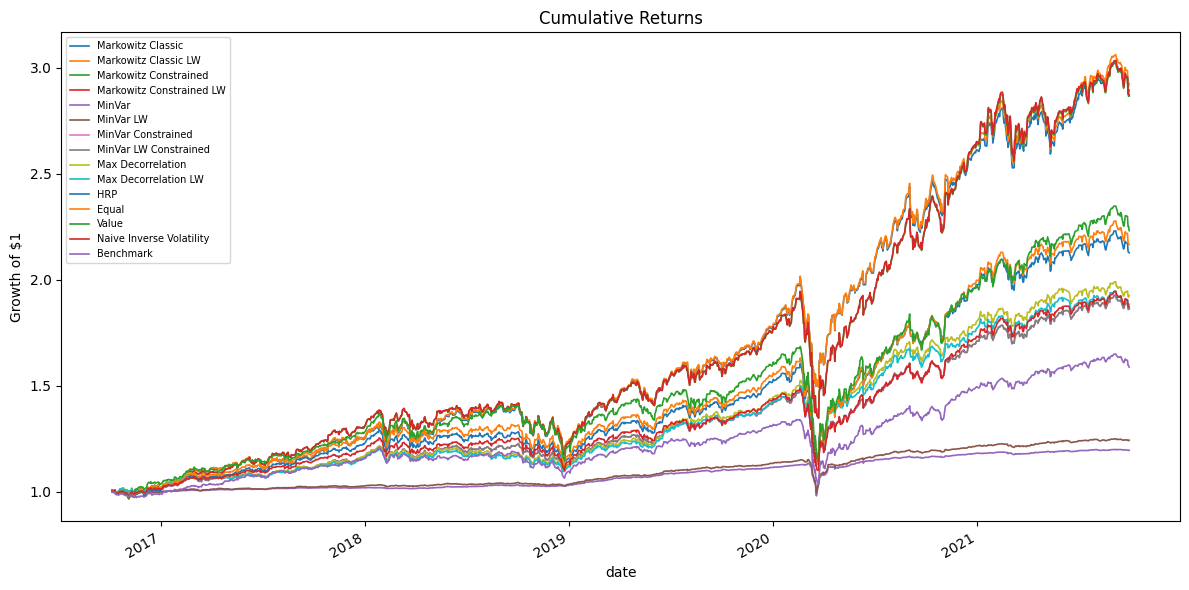

In [8]:
# ===============================
# Plot results
# ===============================

# --- Portfolio time series construction ---
portfolios = {
    "Markowitz Classic": port_metrics_compute_portfolio_series(weights_markowitz_classic_series, returns_frame),
    "Markowitz Classic LW": port_metrics_compute_portfolio_series(weights_markowitz_classic_lw_series, returns_frame),
    "Markowitz Constrained": port_metrics_compute_portfolio_series(weights_markowitz_constrained_series, returns_frame),
    "Markowitz Constrained LW": port_metrics_compute_portfolio_series(weights_markowitz_constrained_lw_series, returns_frame),

    "MinVar": port_metrics_compute_portfolio_series(weights_minvar_series, returns_frame),
    "MinVar LW": port_metrics_compute_portfolio_series(weights_minvar_lw_series, returns_frame),
    "MinVar Constrained": port_metrics_compute_portfolio_series(weights_minvar_constrained_series, returns_frame),
    "MinVar LW Constrained": port_metrics_compute_portfolio_series(weights_minvar_constrained_lw_series, returns_frame),

    "Max Decorrelation": port_metrics_compute_portfolio_series(weights_decorrel_series, returns_frame),
    "Max Decorrelation LW": port_metrics_compute_portfolio_series(weights_decorrel_lw_series, returns_frame),

    "HRP": port_metrics_compute_portfolio_series(weights_riskparity_series, returns_frame),

    "Equal": port_metrics_compute_portfolio_series(weights_equal_series, returns_frame),
    "Value": port_metrics_compute_portfolio_series(weights_value_series, returns_frame),

    "Naive Inverse Volatility": port_metrics_compute_portfolio_series(weights_inversevol_series, returns_frame),

    "Benchmark": benchmark_return_series,
}

# --- Enforce consistent order for plotting ---
ordered_names = [
    "Markowitz Classic", "Markowitz Classic LW",
    "Markowitz Constrained", "Markowitz Constrained LW",
    "MinVar", "MinVar LW", "MinVar Constrained", "MinVar LW Constrained",
    "Max Decorrelation", "Max Decorrelation LW",
    "HRP", 
    "Equal",
    "Value", 
    "Naive Inverse Volatility",
    "Benchmark"
]

# --- Build wealth index for all portfolios ---
wealth = pd.DataFrame({name: (1 + portfolios[name]).cumprod() for name in ordered_names})
wealth.plot(figsize=(12, 6), title="Cumulative Returns", lw=1.2)
plt.ylabel("Growth of $1")
plt.legend(loc="best", fontsize=7)
plt.tight_layout()
plt.show()

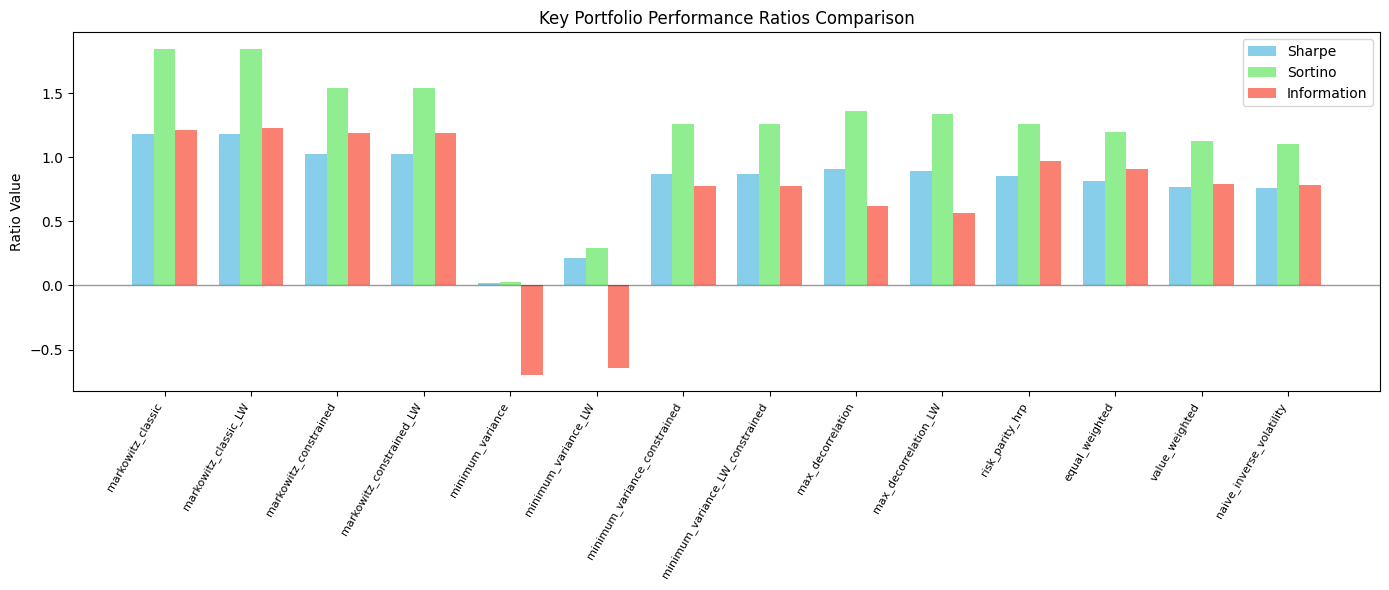

In [9]:
# ===============================
# Ratios Comparison Plot
# ===============================

# --- Extract key metrics in the same order (excluding benchmark) ---
plot_metrics = metrics_table.loc[
    [
        "markowitz_classic", "markowitz_classic_LW",
        "markowitz_constrained", "markowitz_constrained_LW",
        "minimum_variance", "minimum_variance_LW",
        "minimum_variance_constrained", "minimum_variance_LW_constrained",
        "max_decorrelation", "max_decorrelation_LW",
        "risk_parity_hrp",
        "equal_weighted",
        "value_weighted",
        "naive_inverse_volatility",
    ],
    ["Sharpe (Ann.)", "Sortino (Ann.)", "Info (Ann.)"]
]


# --- Create grouped bar chart ---
plt.figure(figsize=(14, 6))
bar_width = 0.25
x = np.arange(len(plot_metrics.index))

plt.bar(x - bar_width, plot_metrics["Sharpe (Ann.)"], width=bar_width, label="Sharpe", color="skyblue")
plt.bar(x, plot_metrics["Sortino (Ann.)"], width=bar_width, label="Sortino", color="lightgreen")
plt.bar(x + bar_width, plot_metrics["Info (Ann.)"], width=bar_width, label="Information", color="salmon")

plt.axhline(0, color="black", lw=1, alpha=0.4)

plt.title("Key Portfolio Performance Ratios Comparison")
plt.ylabel("Ratio Value")
plt.xticks(x, plot_metrics.index, rotation=60, ha="right", fontsize=8)
plt.legend()
plt.tight_layout()
plt.show()

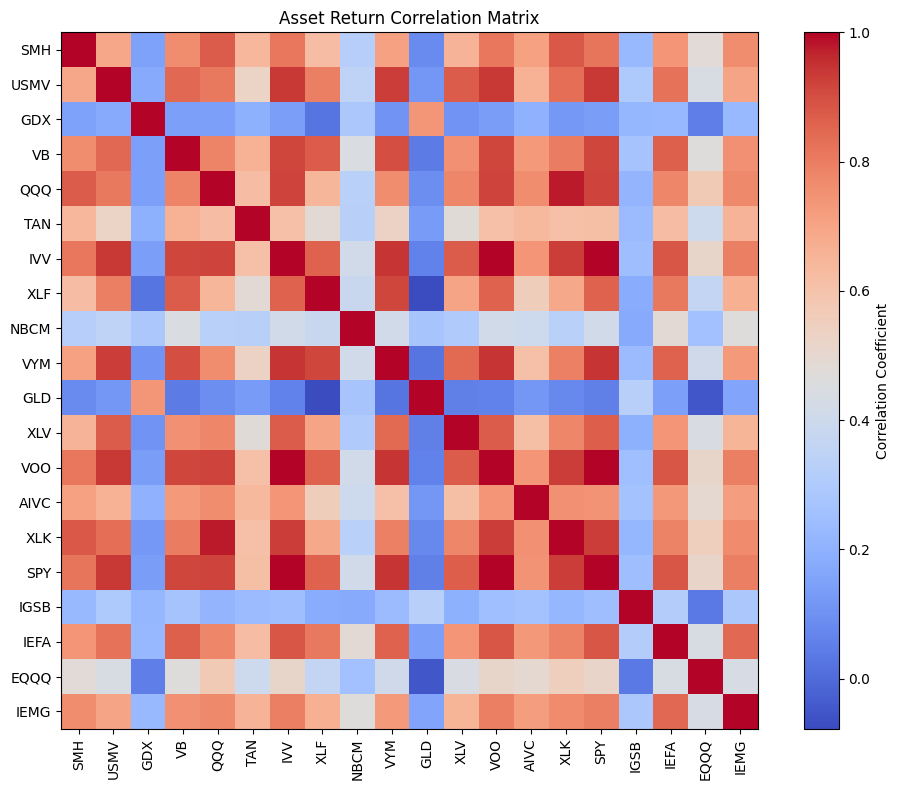


=== Correlation Summary ===
Average pairwise correlation: 0.550
Highest correlation pair: ('IVV', 'VOO') = 0.999
Lowest correlation pair: ('XLF', 'GLD') = -0.077


In [10]:
# ===============================
# Correlation Matrix (Assets Only)
# ===============================

# Compute correlation matrix (excluding benchmark)
corr_frame = returns_frame.corr()

# --- Plot correlation heatmap ---
plt.figure(figsize=(10, 8))
plt.imshow(corr_frame, cmap="coolwarm", interpolation="nearest")
plt.colorbar(label="Correlation Coefficient")
plt.xticks(ticks=np.arange(len(corr_frame.columns)), labels=corr_frame.columns, rotation=90)
plt.yticks(ticks=np.arange(len(corr_frame.columns)), labels=corr_frame.columns)
plt.title("Asset Return Correlation Matrix")
plt.tight_layout()
plt.show()

# --- Optional: print summary statistics (excluding self-correlation) ---
corr_values = corr_frame.where(~np.eye(len(corr_frame), dtype=bool))  # mask diagonal
corr_stack = corr_values.stack()

avg_corr = corr_stack.mean()
max_pair = corr_stack.idxmax()
min_pair = corr_stack.idxmin()

print("\n=== Correlation Summary ===")
print(f"Average pairwise correlation: {avg_corr:.3f}")
print(f"Highest correlation pair: {max_pair} = {corr_stack[max_pair]:.3f}")
print(f"Lowest correlation pair: {min_pair} = {corr_stack[min_pair]:.3f}")

Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


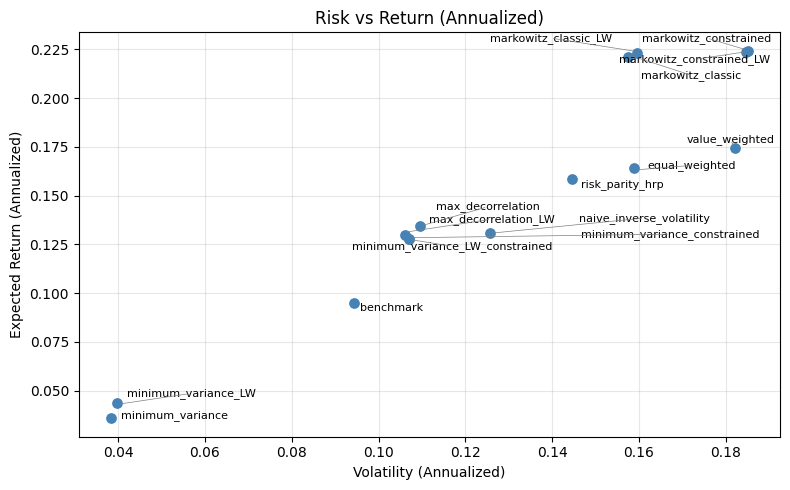

In [11]:
# ===============================
# Risk–Return Scatter
# ===============================

plt.figure(figsize=(8,5))

# Use updated column names
x = metrics_table["Vol (Ann.)"]
y = metrics_table["Return (Ann.)"]

plt.scatter(x, y, color="steelblue", s=45, zorder=3)

# Add a little jitter to avoid label overlap
y_jittered = y + np.random.uniform(-0.0015, 0.0015, size=len(y))

texts = []
for i, txt in enumerate(metrics_table.index):
    texts.append(
        plt.text(
            x.iloc[i],
            y_jittered.iloc[i],
            txt,
            fontsize=8,
            ha="left",
            va="bottom"
        )
    )

# Auto-adjust label positions to reduce overlap
adjust_text(
    texts,
    expand_points=(1.3, 1.4),
    expand_text=(1.3, 1.4),
    arrowprops=dict(arrowstyle="-", color="gray", lw=0.5),
    only_move={'points': 'y', 'text': 'xy'}
)

plt.title("Risk vs Return (Annualized)", fontsize=12)
plt.xlabel("Volatility (Annualized)", fontsize=10)
plt.ylabel("Expected Return (Annualized)", fontsize=10)
plt.grid(True, alpha=0.3, zorder=0)
plt.tight_layout()
plt.show()

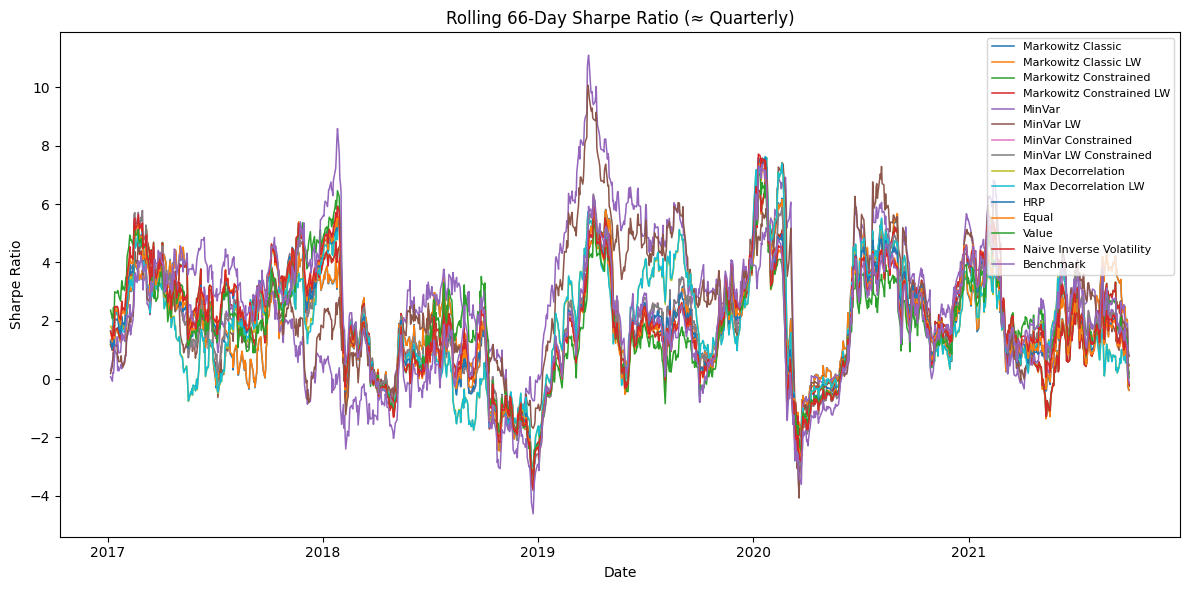

In [12]:
# ===============================
# Rolling Sharpe Ratios
# ===============================

window_days = 66  # ~quarterly window
plt.figure(figsize=(12, 6))

for name in ordered_names:
    series = portfolios[name]
    rolling_mean = series.rolling(window_days).mean()
    rolling_std = series.rolling(window_days).std()
    rolling_sharpe = (rolling_mean / rolling_std) * np.sqrt(trading_days_per_year)
    plt.plot(rolling_sharpe, lw=1.1, label=name)

plt.title(f"Rolling {window_days}-Day Sharpe Ratio (≈ Quarterly)", fontsize=12)
plt.ylabel("Sharpe Ratio", fontsize=10)
plt.xlabel("Date", fontsize=10)
plt.legend(loc="best", fontsize=8)
plt.tight_layout()
plt.show()

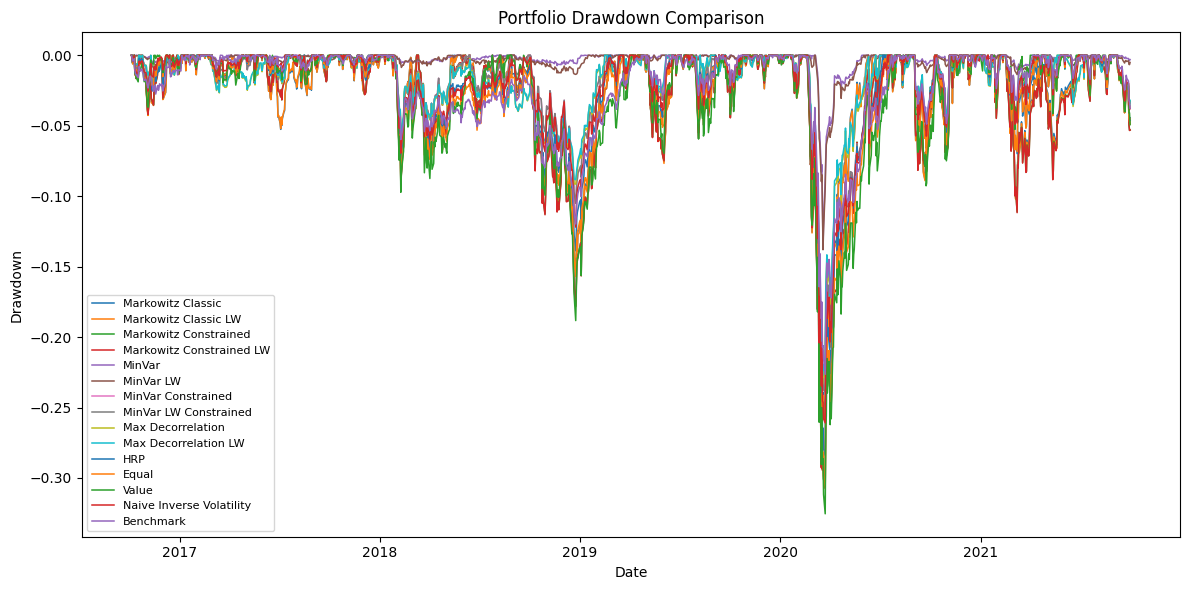

In [13]:
# ===============================
# Portfolio Drawdowns
# ===============================

plt.figure(figsize=(12, 6))
for name in ordered_names:
    series = portfolios[name]
    cum_returns = (1 + series).cumprod()
    drawdowns = cum_returns / cum_returns.cummax() - 1
    plt.plot(drawdowns, lw=1.1, label=name)

plt.title("Portfolio Drawdown Comparison", fontsize=12)
plt.ylabel("Drawdown", fontsize=10)
plt.xlabel("Date", fontsize=10)
plt.legend(loc="best", fontsize=8)
plt.tight_layout()
plt.show()

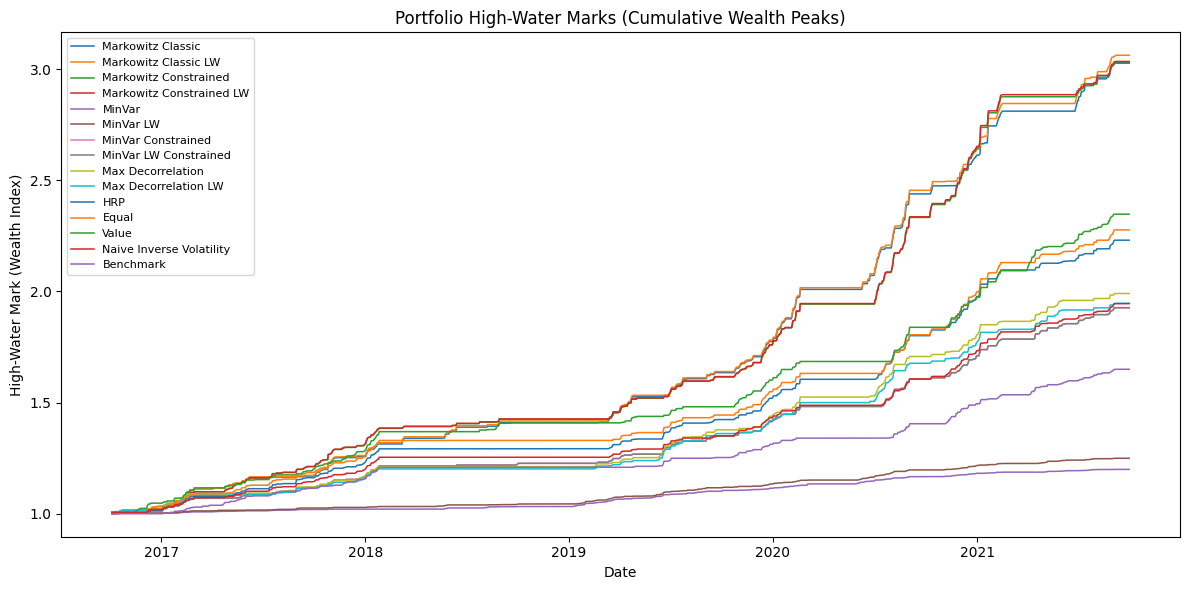

In [14]:
# ===============================
# Portfolio High-Water Marks
# ===============================

plt.figure(figsize=(12, 6))
for name in ordered_names:
    series = portfolios[name]
    cum_returns = (1 + series).cumprod()
    hwm_series = cum_returns.cummax()
    plt.plot(hwm_series, lw=1.1, label=name)

plt.title("Portfolio High-Water Marks (Cumulative Wealth Peaks)", fontsize=12)
plt.ylabel("High-Water Mark (Wealth Index)", fontsize=10)
plt.xlabel("Date", fontsize=10)
plt.legend(loc="best", fontsize=8)
plt.tight_layout()
plt.show()


=== CAPM Regression: Portfolio Returns vs Benchmark ===
             Markowitz Classic | alpha: 0.000390 | beta: 1.288 | t(alpha): 2.21 (SIGNIFICANT) | R²: 0.596


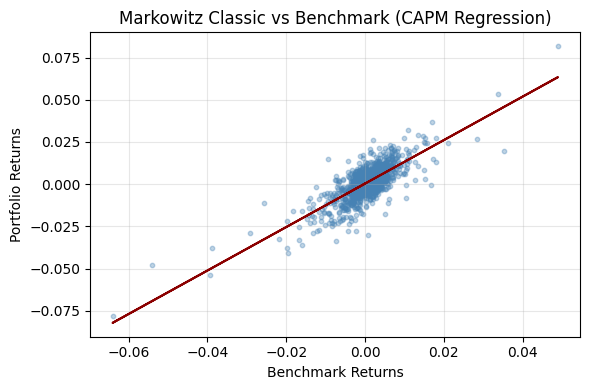

          Markowitz Classic LW | alpha: 0.000389 | beta: 1.316 | t(alpha): 2.21 (SIGNIFICANT) | R²: 0.606


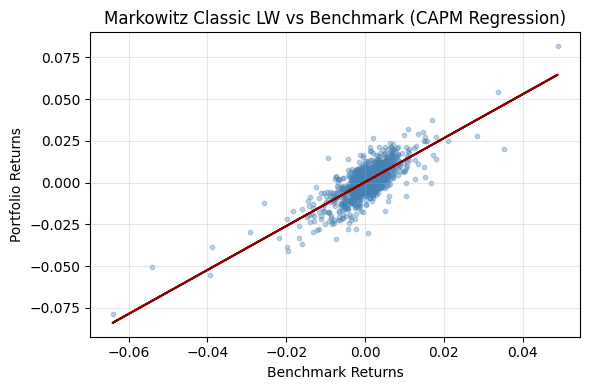

         Markowitz Constrained | alpha: 0.000225 | beta: 1.756 | t(alpha): 1.56 (n.s.) | R²: 0.805


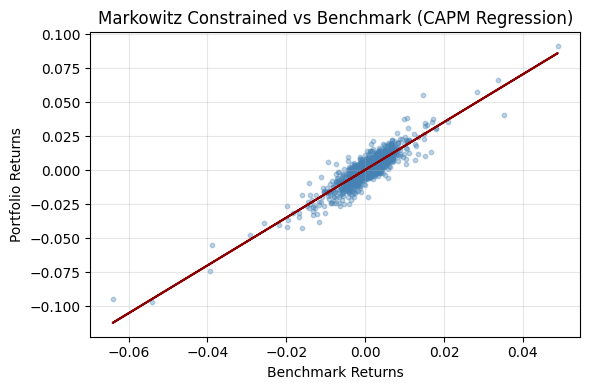

      Markowitz Constrained LW | alpha: 0.000225 | beta: 1.760 | t(alpha): 1.56 (n.s.) | R²: 0.804


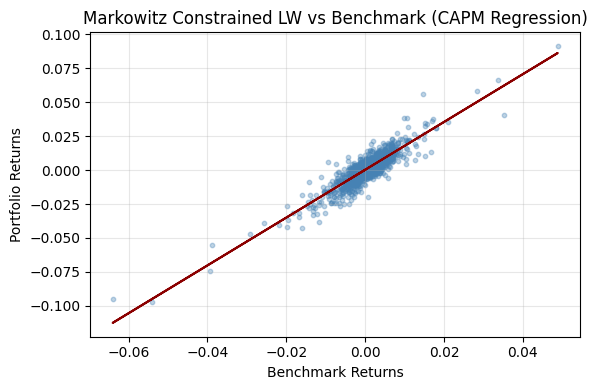

                        MinVar | alpha: 0.000076 | beta: 0.176 | t(alpha): 1.24 (n.s.) | R²: 0.189


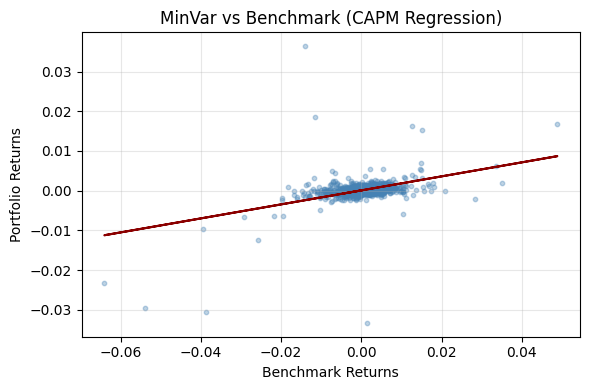

                     MinVar LW | alpha: 0.000087 | beta: 0.227 | t(alpha): 1.47 (n.s.) | R²: 0.290


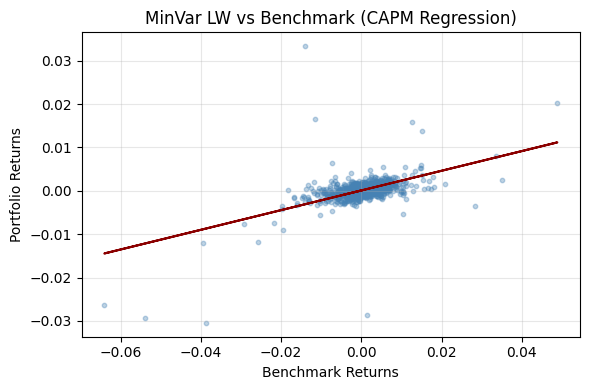

            MinVar Constrained | alpha: 0.000112 | beta: 1.046 | t(alpha): 1.53 (n.s.) | R²: 0.848


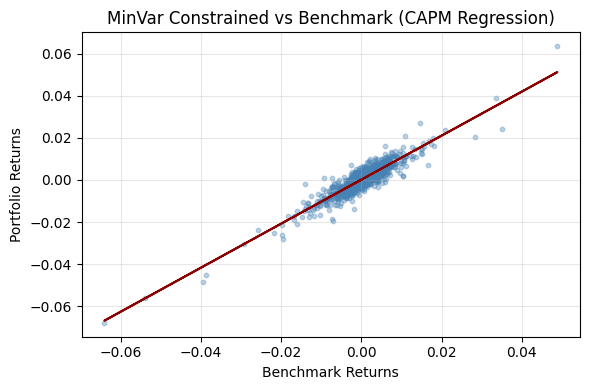

         MinVar LW Constrained | alpha: 0.000112 | beta: 1.046 | t(alpha): 1.53 (n.s.) | R²: 0.848


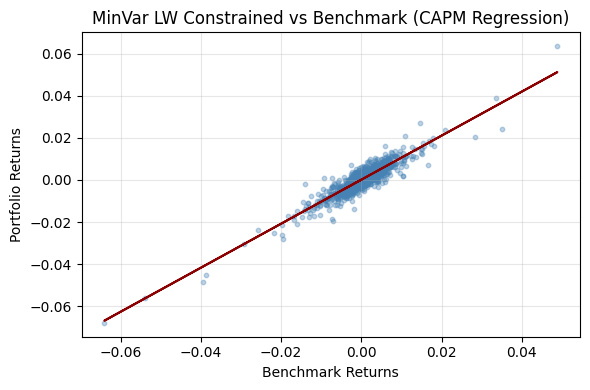

             Max Decorrelation | alpha: 0.000177 | beta: 0.946 | t(alpha): 1.58 (n.s.) | R²: 0.663


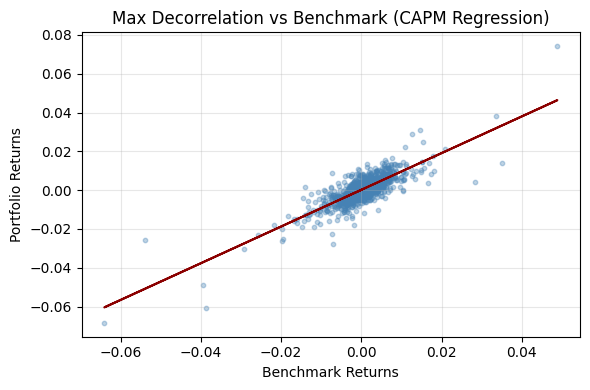

          Max Decorrelation LW | alpha: 0.000169 | beta: 0.917 | t(alpha): 1.57 (n.s.) | R²: 0.665


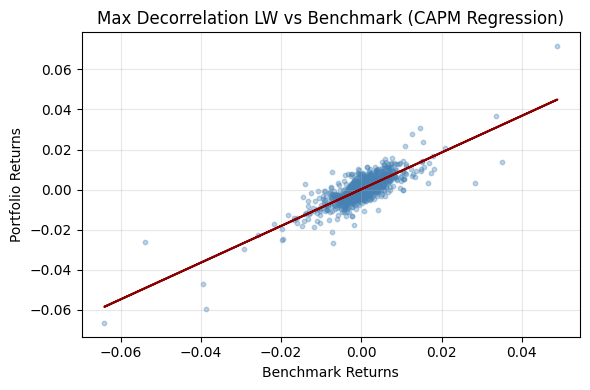

                           HRP | alpha: 0.000087 | beta: 1.436 | t(alpha): 0.98 (n.s.) | R²: 0.878


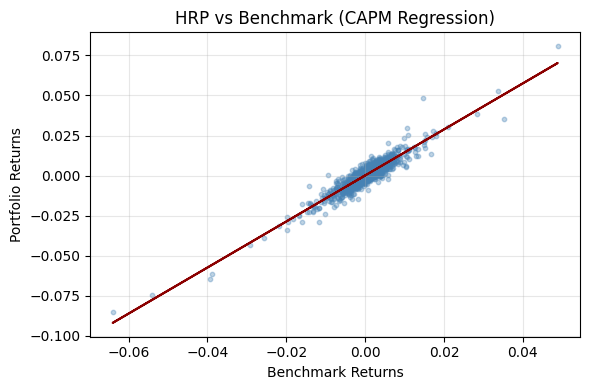

                         Equal | alpha: 0.000051 | beta: 1.592 | t(alpha): 0.55 (n.s.) | R²: 0.893


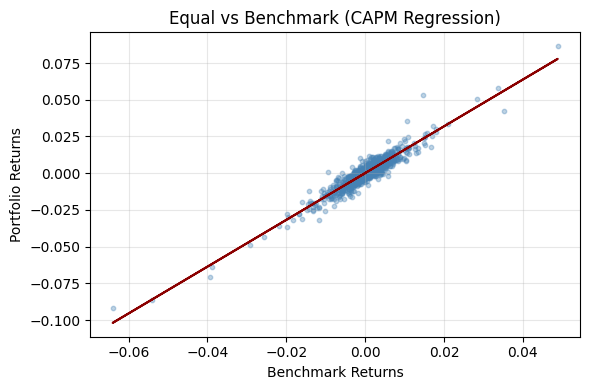

                         Value | alpha: 0.000008 | beta: 1.810 | t(alpha): 0.07 (n.s.) | R²: 0.878


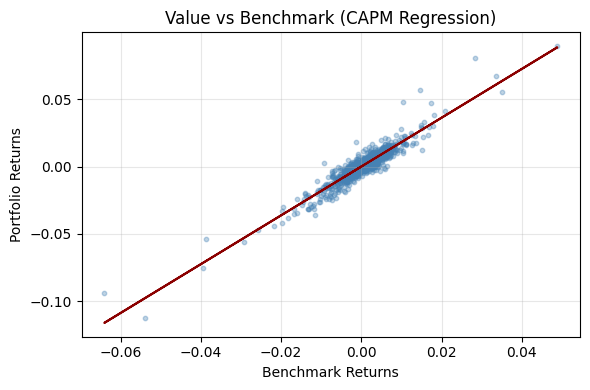

      Naive Inverse Volatility | alpha: 0.000039 | beta: 1.271 | t(alpha): 0.59 (n.s.) | R²: 0.909


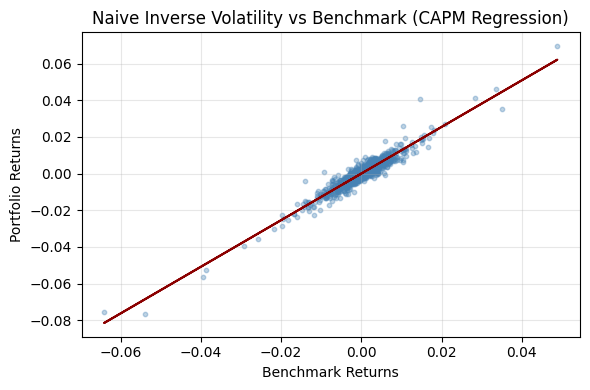

                     Benchmark | alpha: -0.000000 | beta: 1.000 | t(alpha): -1.68 (n.s.) | R²: 1.000


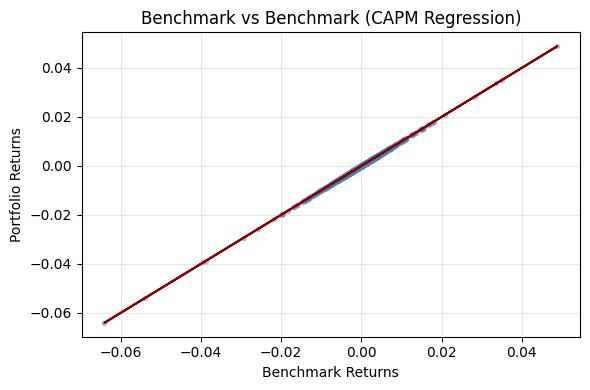


=== CAPM Regression Summary Table ===
                           Alpha  t(Alpha)    Beta      R²  p(Alpha)  \
Markowitz Classic         0.0004    2.2115  1.2883  0.5955    0.0272   
Markowitz Classic LW      0.0004    2.2060  1.3160  0.6059    0.0276   
Markowitz Constrained     0.0002    1.5640  1.7555  0.8048    0.1181   
Markowitz Constrained LW  0.0002    1.5603  1.7602  0.8039    0.1189   
MinVar                    0.0001    1.2433  0.1763  0.1889    0.2140   
MinVar LW                 0.0001    1.4727  0.2268  0.2897    0.1411   
MinVar Constrained        0.0001    1.5259  1.0460  0.8483    0.1273   
MinVar LW Constrained     0.0001    1.5259  1.0460  0.8483    0.1273   
Max Decorrelation         0.0002    1.5798  0.9457  0.6632    0.1144   
Max Decorrelation LW      0.0002    1.5681  0.9166  0.6654    0.1171   
HRP                       0.0001    0.9774  1.4364  0.8781    0.3286   
Equal                     0.0001    0.5539  1.5917  0.8928    0.5798   
Value                    

In [15]:
# ===============================
# Regression Analysis vs Benchmark (CAPM)
# ===============================

print("\n" + "=" * 90)
print("=== CAPM Regression: Portfolio Returns vs Benchmark ===")
print("=" * 90)

alphas = {}
betas = {}
t_alphas = {}
r2s = {}
pvals = {}

for name in ordered_names:
    series = portfolios[name]

    # --- Align with benchmark ---
    reg_data = pd.concat([series, benchmark_return_series], axis=1).dropna()
    reg_data.columns = ["portfolio", "benchmark"]

    # --- CAPM model: portfolio = alpha + beta * benchmark + ε ---
    X = sm.add_constant(reg_data["benchmark"])
    model = sm.OLS(reg_data["portfolio"], X).fit()

    alphas[name] = model.params["const"]
    betas[name] = model.params["benchmark"]
    t_alphas[name] = model.tvalues["const"]
    r2s[name] = model.rsquared
    pvals[name] = model.pvalues["const"]

    # --- Significance status ---
    significance = "SIGNIFICANT" if abs(model.tvalues["const"]) >= 1.96 else "n.s."

    print(
        f"{name:>30s} | "
        f"alpha: {model.params['const']:.6f} "
        f"| beta: {model.params['benchmark']:.3f} "
        f"| t(alpha): {model.tvalues['const']:.2f} ({significance}) "
        f"| R²: {model.rsquared:.3f}"
    )

    # --- Plot regression line ---
    plt.figure(figsize=(6, 4))
    plt.scatter(reg_data["benchmark"], reg_data["portfolio"], alpha=0.35, color="steelblue", s=10)
    plt.plot(reg_data["benchmark"], model.predict(X), color="darkred", lw=1.5)
    plt.title(f"{name} vs Benchmark (CAPM Regression)")
    plt.xlabel("Benchmark Returns")
    plt.ylabel("Portfolio Returns")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# --- CAPM Summary Table ---
capm_table = pd.DataFrame({
    "Alpha": pd.Series(alphas),
    "t(Alpha)": pd.Series(t_alphas),
    "Beta": pd.Series(betas),
    "R²": pd.Series(r2s),
    "p(Alpha)": pd.Series(pvals)
}).round(4)

# Add a flag for significance (two-tailed 5%)
capm_table["Alpha Sig."] = np.where(abs(capm_table["t(Alpha)"]) >= 1.96, "Yes", "No")

capm_table = capm_table.loc[ordered_names]  # keep family order

print("\n=== CAPM Regression Summary Table ===")
print(capm_table)

print("\nInterpretation:")
print("• Alpha: daily excess return unexplained by benchmark.")
print("• t(Alpha): test statistic for Alpha’s significance (|t| ≥ 1.96 ⇒ significant at 5%).")
print("• Beta: sensitivity to benchmark.")
print("• R²: explanatory power of CAPM model.\n")

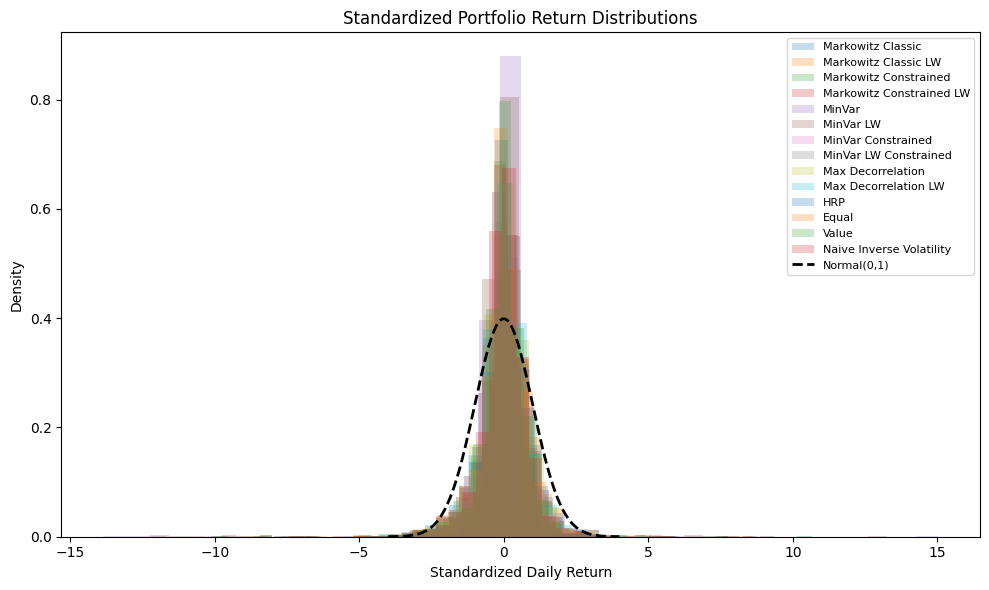


=== Return Distribution Normality Diagnostics ===
                          skewness  kurtosis  tail_excess
Markowitz Classic LW        -0.448    11.876        8.876
Markowitz Classic           -0.428    11.975        8.975
Markowitz Constrained LW    -0.789    16.764       13.764
Markowitz Constrained       -0.788    16.812       13.812
Value                       -0.876    22.646       19.646
HRP                         -1.068    22.984       19.984
Equal                       -1.068    23.005       20.005
MinVar Constrained          -1.269    25.879       22.879
MinVar LW Constrained       -1.269    25.879       22.879
Naive Inverse Volatility    -1.353    27.062       24.062
Max Decorrelation           -0.771    28.862       25.862
Max Decorrelation LW        -0.814    29.177       26.177
MinVar LW                   -2.257    87.763       84.763
MinVar                      -2.291   121.984      118.984

Portfolio closest to Normal: Markowitz Classic LW (kurtosis = 11.876)
Portfoli

In [16]:
# ===============================
# Portfolio Return Distributions (Normal Comparison + Stats)
# ===============================

plt.figure(figsize=(10, 6))

dist_stats = {}

for name, series in portfolios.items():
    if name == "Benchmark":
        continue

    # Standardize returns (zero mean, unit std)
    standardized = (series - series.mean()) / series.std()

    # Save skewness and kurtosis for summary
    dist_stats[name] = {
        "skewness": skew(standardized, bias=False),
        "kurtosis": kurtosis(standardized, fisher=False),  # normal=3
    }

    # Plot histogram
    plt.hist(
        standardized,
        bins=40,
        density=True,
        alpha=0.25,
        label=name
    )

# Overlay standard normal curve
x_vals = np.linspace(-4, 4, 200)
plt.plot(x_vals, norm.pdf(x_vals), "k--", lw=2, label="Normal(0,1)")

plt.title("Standardized Portfolio Return Distributions")
plt.xlabel("Standardized Daily Return")
plt.ylabel("Density")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()


# --- Summary statistics ---
print("\n=== Return Distribution Normality Diagnostics ===")
summary_df = pd.DataFrame(dist_stats).T.round(3)
summary_df["tail_excess"] = summary_df["kurtosis"] - 3  # excess kurtosis
print(summary_df.sort_values("kurtosis", ascending=True))

# Identify most/least normal
most_normal = summary_df["kurtosis"].sub(3).abs().idxmin()
fattest_tails = summary_df["kurtosis"].idxmax()

print(f"\nPortfolio closest to Normal: {most_normal} (kurtosis = {summary_df.loc[most_normal, 'kurtosis']:.3f})")
print(f"Portfolio with fattest tails: {fattest_tails} (kurtosis = {summary_df.loc[fattest_tails, 'kurtosis']:.3f})")


=== GARCH(1,1) Conditional Volatility (In-Sample Period) ===
[INFO] GARCH(1,1) fitted for Markowitz Classic (obs: 1285)
[INFO] GARCH(1,1) fitted for Markowitz Classic LW (obs: 1285)
[INFO] GARCH(1,1) fitted for Markowitz Constrained (obs: 1285)
[INFO] GARCH(1,1) fitted for Markowitz Constrained LW (obs: 1285)
[INFO] GARCH(1,1) fitted for MinVar (obs: 1285)
[INFO] GARCH(1,1) fitted for MinVar LW (obs: 1285)
[INFO] GARCH(1,1) fitted for MinVar Constrained (obs: 1285)
[INFO] GARCH(1,1) fitted for MinVar LW Constrained (obs: 1285)
[INFO] GARCH(1,1) fitted for Max Decorrelation (obs: 1285)
[INFO] GARCH(1,1) fitted for Max Decorrelation LW (obs: 1285)
[INFO] GARCH(1,1) fitted for HRP (obs: 1285)
[INFO] GARCH(1,1) fitted for Equal (obs: 1285)
[INFO] GARCH(1,1) fitted for Value (obs: 1285)
[INFO] GARCH(1,1) fitted for Naive Inverse Volatility (obs: 1285)
[INFO] GARCH(1,1) fitted for Benchmark (obs: 1285)


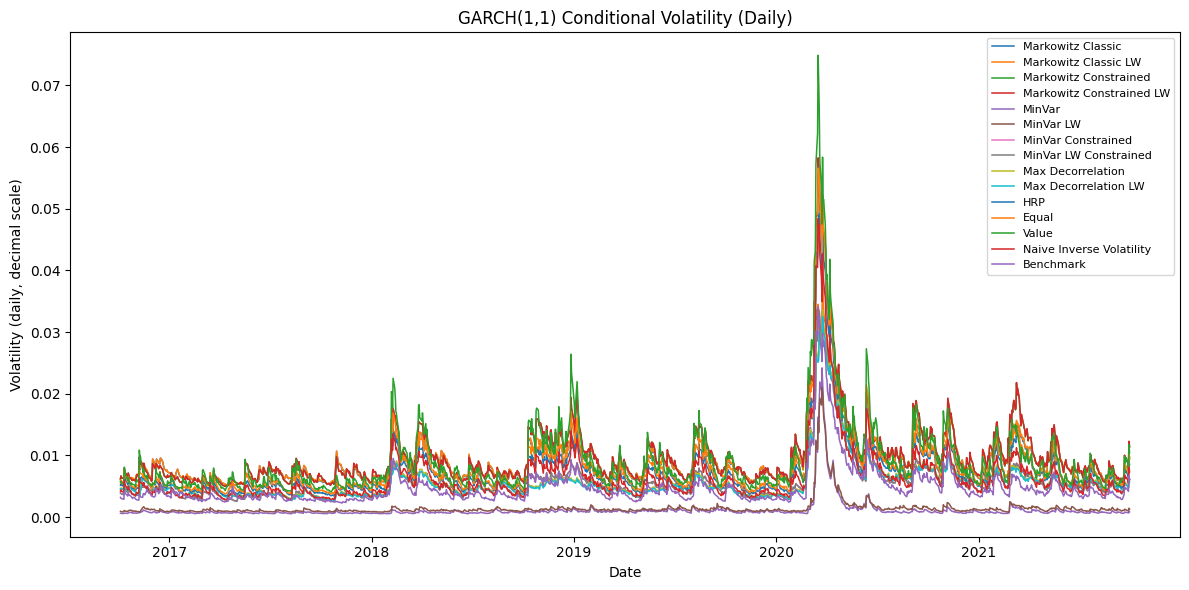

In [17]:
# ==================================================
# Conditional Volatility via GARCH(1,1) — In-Sample
# ==================================================

print("\n" + "="*90)
print("=== GARCH(1,1) Conditional Volatility (In-Sample Period) ===")
print("="*90)

# Prepare In-Sample data
returns_is = {m: s.loc[: "2021-09-30"] for m, s in portfolios.items() if not s.empty}

# Fit and collect conditional volatility series
garch_vols_is = {}

for name, series in returns_is.items():
    try:
        # remove NaNs and ensure mean-centered
        r = series.dropna() * 100  # scale to % for numerical stability
        model = arch_model(r, vol="Garch", p=1, q=1, mean="Zero")
        res = model.fit(disp="off")
        cond_vol = res.conditional_volatility / 100  # back to decimal scale
        garch_vols_is[name] = cond_vol
        print(f"[INFO] GARCH(1,1) fitted for {name} (obs: {len(r)})")
    except Exception as e:
        print(f"[WARN] {name}: GARCH fitting failed ({e})")

# --- Plot all conditional volatilities (In-Sample) ---
plt.figure(figsize=(12, 6))
for name, v in garch_vols_is.items():
    plt.plot(v.index, v, lw=1.1, label=name)
plt.title("GARCH(1,1) Conditional Volatility (Daily)", fontsize=12)
plt.ylabel("Volatility (daily, decimal scale)")
plt.xlabel("Date")
plt.legend(loc="best", fontsize=8)
plt.tight_layout()
plt.show()